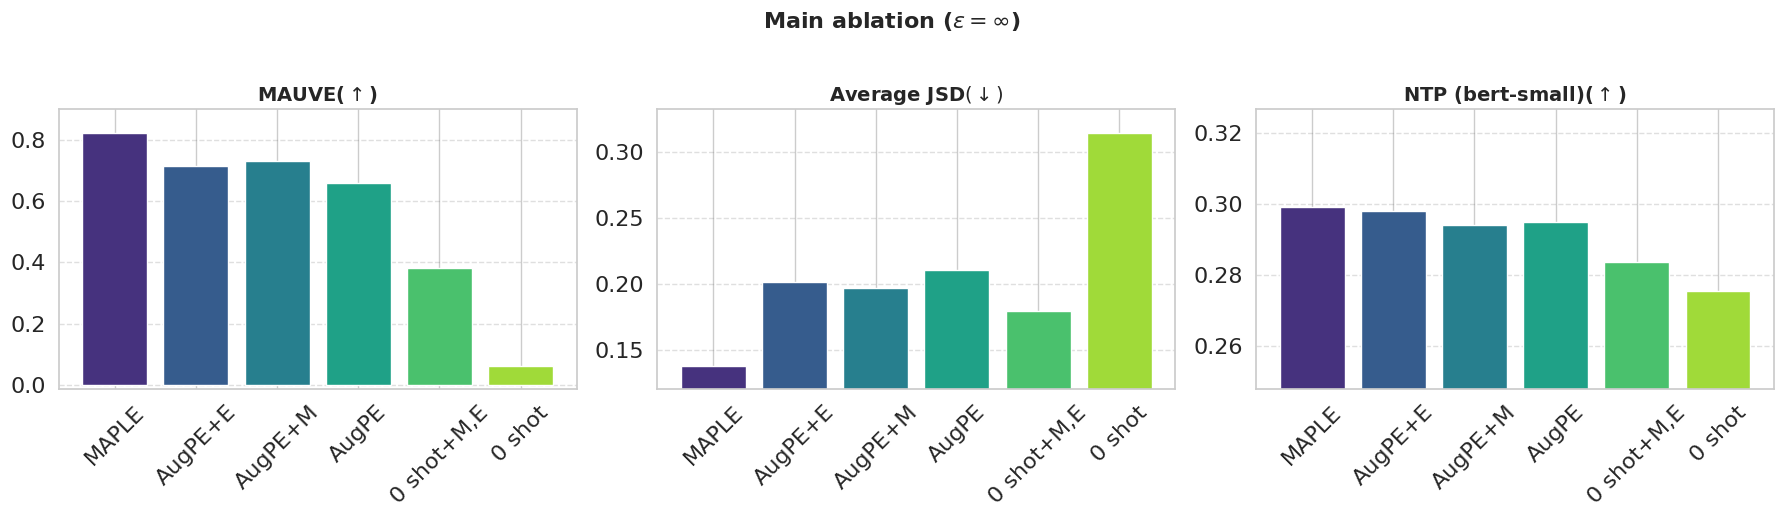

In [244]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_experiment_results(results, metric_names, title='Comparison of Methods For Each Metric', ylabel=None):
    """
    Generates and displays a set of horizontal bar plots for experiment results,
    with each metric in a separate subplot.

    Args:
        results (dict): A dictionary where keys are method names (str) and
                        values are numpy arrays of metric scores.
        metric_names (list): A list of strings with the names of the metrics.
    """
    # --- 1. Data Preparation ---
    method_names = list(results.keys())
    scores = np.array(list(results.values()))
    num_methods = len(method_names)
    num_metrics = len(metric_names)

    # --- 2. Plotting Setup ---
    # Set the seaborn style for a professional look
    sns.set_theme(style="whitegrid")

    # Create a figure with a subplot for each metric, arranged horizontally
    fig, axes = plt.subplots(nrows=1, ncols=num_metrics, figsize=(6 * num_metrics, 5))

    # If there's only one metric, plt.subplots returns a single axis object.
    # We'll wrap it in a list to make the looping code consistent.
    if num_metrics == 1:
        axes = [axes]

    # Define a color palette to use for the methods
    colors = sns.color_palette("viridis", num_methods)

    # --- 3. Generate a Bar Plot for Each Metric ---
    for i, ax in enumerate(axes):
        # Extract the scores for the current metric across all methods
        metric_scores = scores[:, i]

        # Create the bar plot for the current metric's subplot
        ax.bar(method_names, metric_scores, color=colors)
        
        # --- 4. Customize Each Subplot ---
        
        # Automatically adjust y-axis to zoom in on the data range
        min_score = np.min(metric_scores)
        max_score = np.max(metric_scores)
        data_range = max_score - min_score

        # Add some padding to the top and bottom of the range
        # If all values are the same, create a small default range
        if data_range < 0.1:
            padding = 0.1 * abs(min_score) if min_score != 0 else 0.1
        else:
            # Add 10% padding to the top and bottom relative to the data range
            padding = data_range * 0.10

        # Set the y-axis limits for the current subplot
        ax.set_ylim([min_score - padding, max_score + padding])
        
        # --- 4. Customize Each Subplot ---
        ax.set_title(metric_names[i], fontweight='bold', fontsize=14)
        # Set larger font size for x-axis labels (method names) and y-axis ticks
        ax.tick_params(axis='x', labelrotation=45, labelsize=16)
        ax.tick_params(axis='y', labelsize=16)
        ax.yaxis.grid(True, linestyle='--', which='major', color='grey', alpha=.25)

    # --- 5. Customize the Overall Figure ---
    fig.suptitle(title, fontweight='bold', fontsize=16, y=1.03)
    if ylabel:
        axes[0].set_ylabel(ylabel, fontweight='bold', fontsize=16)
    
    
    # Improve the layout to prevent labels from overlapping
    fig.tight_layout()

    # --- 6. Show the Plot ---
    plt.show()

if __name__ == '__main__':
    # --- Example Usage ---
    
    # Your experiment results
    my_results = {
        # 'MAPLE (with R)': np.array([0.8517,0.1459,0.3017]),
        # 'AugPE+E,R': np.array([0.5294,0.4305,0.3047]),
        # 'AugPE+M,R': np.array([0.4183,0.1280,0.2765]),
        # 'AugPE+R': np.array([0.3057,0.6190,0.2941]),
        'MAPLE': np.array([0.8244,0.1378,0.2992]),
        'AugPE+E': np.array([0.7140,0.2016,0.2981]),
        'AugPE+M': np.array([0.7332,0.1966,0.2940]),
        'AugPE': np.array([0.6605,0.210624,0.2950]),
        '0 shot+M,E': np.array([0.3813,0.1793,0.2836]),
        '0 shot': np.array([0.0626,0.314848,0.2753]),
    }

    # Names of the metrics corresponding to the array values
    my_metric_names = [r'MAUVE($\uparrow$)',r"Average JSD$(\downarrow)$", r'NTP (bert-small)($\uparrow$)']

    # Call the function with your data
    plot_experiment_results(my_results, my_metric_names, title=r'Main ablation ($\epsilon=\infty$)')

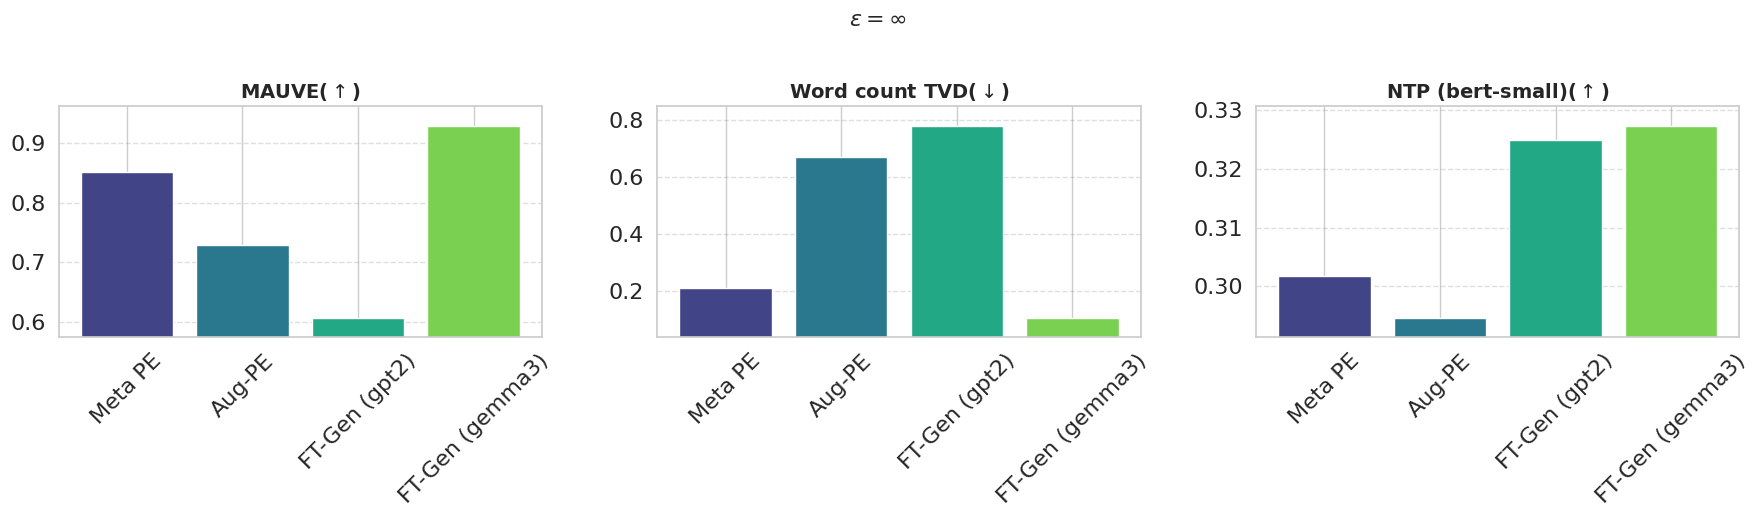

In [79]:
# Your experiment results
my_results = {
    'Meta PE': np.array([0.8517,0.2090,0.3017]),
    'Aug-PE': np.array([0.7296,0.6695,0.2946]),
    'FT-Gen (gpt2)': np.array([0.6065,0.7805,0.3250]),
    'FT-Gen (gemma3)': np.array([0.9291,0.1040,0.3274]),
}

# Names of the metrics corresponding to the array values
my_metric_names = [r'MAUVE($\uparrow$)',r'Word count TVD($\downarrow$)', r'NTP (bert-small)($\uparrow$)']

# Call the function with your data
plot_experiment_results(my_results, my_metric_names, title = r'$\varepsilon = \infty$')

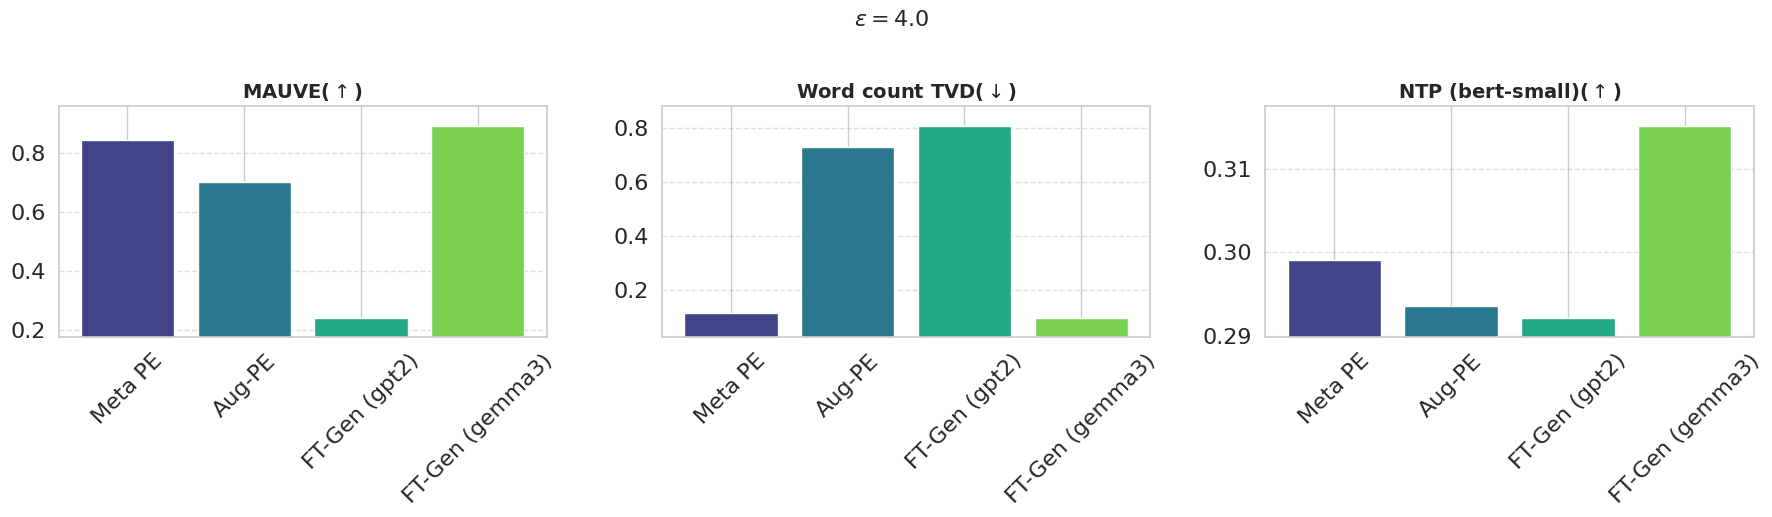

In [80]:
# Your experiment results
my_results = {
    'Meta PE': np.array([0.8442,0.1150,0.2991]),
    'Aug-PE': np.array([0.6998,0.7320,0.2935]),
    'FT-Gen (gpt2)': np.array([0.2415,0.8100,0.2921]),
    'FT-Gen (gemma3)': np.array([0.8913,0.0975,0.3152]),
}

# Names of the metrics corresponding to the array values
my_metric_names = [r'MAUVE($\uparrow$)',r'Word count TVD($\downarrow$)', r'NTP (bert-small)($\uparrow$)']

# Call the function with your data
plot_experiment_results(my_results, my_metric_names, title = r'$\varepsilon = 4.0$')

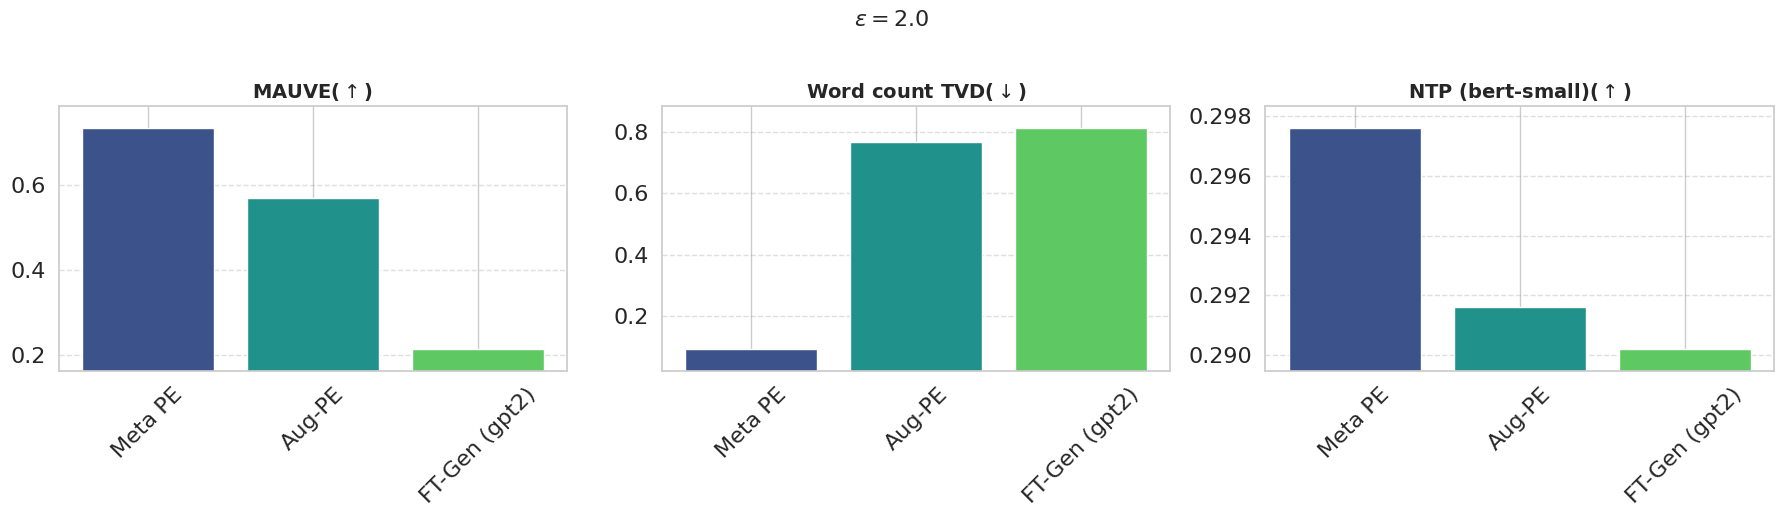

In [122]:
# Your experiment results
my_results = {
    'Meta PE': np.array([0.7325,0.0930,0.2976]),
    'Aug-PE': np.array([0.5688,0.7650,0.2916]),
    'FT-Gen (gpt2)': np.array([0.2140,0.8105,0.2902]),
    # 'FT-Gen (gemma3)': np.array([0.8913,0.0975,0.3152]),
}

# Names of the metrics corresponding to the array values
my_metric_names = [r'MAUVE($\uparrow$)',r'Word count TVD($\downarrow$)', r'NTP (bert-small)($\uparrow$)']

# Call the function with your data
plot_experiment_results(my_results, my_metric_names, title = r'$\varepsilon = 2.0$')

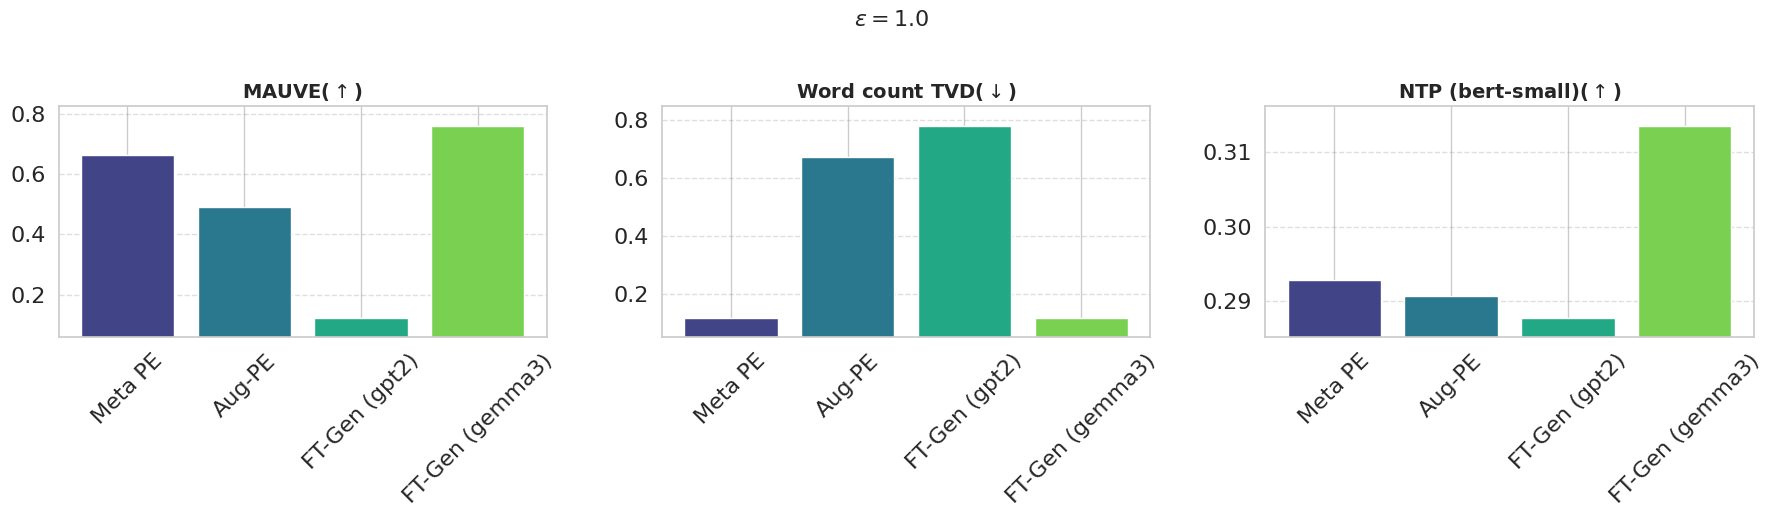

In [81]:
# Your experiment results
my_results = {
    'Meta PE': np.array([0.6645,0.1165,0.2928]),
    'Aug-PE': np.array([0.4924,0.6710,0.2907]),
    'FT-Gen (gpt2)': np.array([0.1217,0.7800,0.2877]),
    'FT-Gen (gemma3)': np.array([0.7623,0.1155,0.3136]),
}

# Names of the metrics corresponding to the array values
my_metric_names = [r'MAUVE($\uparrow$)',r'Word count TVD($\downarrow$)', r'NTP (bert-small)($\uparrow$)']

# Call the function with your data
plot_experiment_results(my_results, my_metric_names, title = r'$\varepsilon = 1.0$')

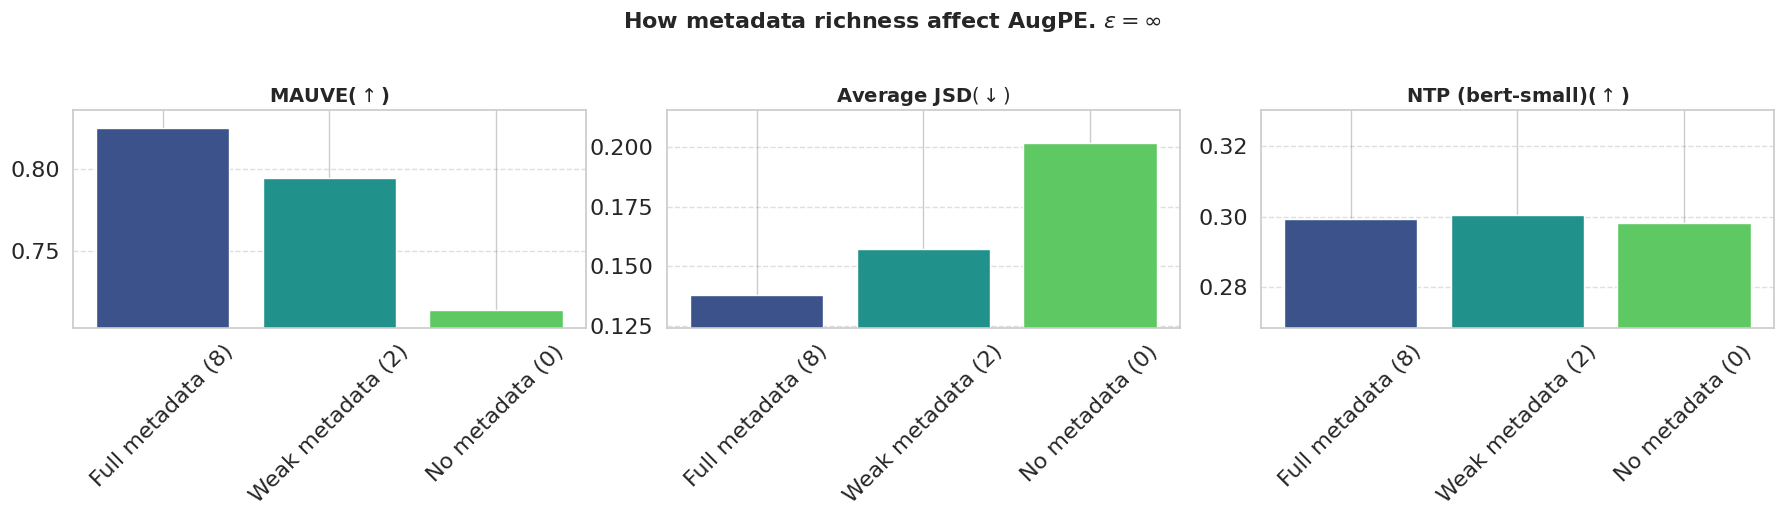

In [155]:
# Your experiment results
my_results = {
    # 'Full metadata (8)': np.array([0.8517,0.145934,0.3017]),
    # 'Weak metadata (4)': np.array([0.7942,0.151889,0.3025]),
    'Full metadata (8)': np.array([0.8244,0.137813,0.2992]),
    'Weak metadata (2)': np.array([0.7945,0.157225,0.3004]),
    'No metadata (0)': np.array([0.7140,0.201631,0.2981]),
}

# Names of the metrics corresponding to the array values
my_metric_names = [r'MAUVE($\uparrow$)',r"Average JSD$(\downarrow)$", r'NTP (bert-small)($\uparrow$)']

# Call the function with your data
plot_experiment_results(my_results, my_metric_names, title = r'How metadata richness affect AugPE. $\varepsilon = \infty$')

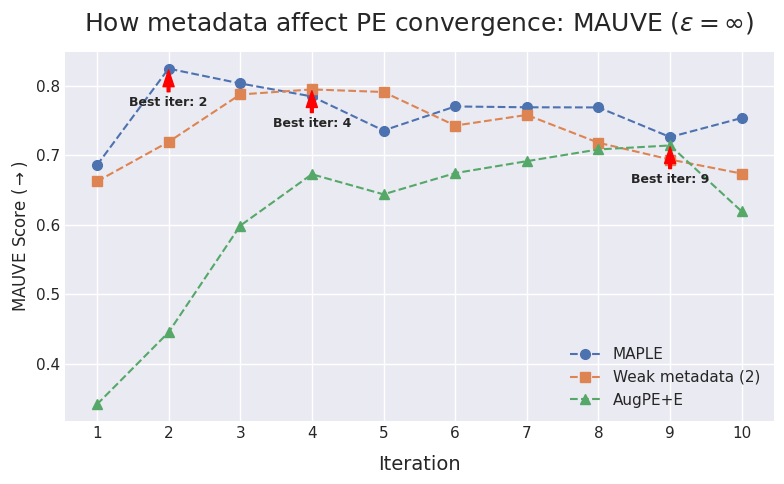

In [265]:
def plot_results(results_dict):
    """
    Creates and displays a single plot for MAUVE scores, highlighting the best
    point for each method with an annotation.
    """
    # --- 1. Apply the requested style ---
    plt.style.use('seaborn-v0_8-darkgrid')

    # Define markers for accessibility
    markers = ['o', 's', '^']
    # Get the number of iterations from the first data array
    num_iterations = list(results_dict.values())[-1].shape[1]
    iterations_axis = np.arange(num_iterations)+1

    # --- 2. Create a SINGLE Subplot ---
    # We only need one plot now, figsize is adjusted.
    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 5))
    # fig, (ax, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(16, 8), sharex=True)

    # --- 3. Plot MAUVE Score and Annotate Best Point ---
    ax.set_title(r'How metadata affect PE convergence: MAUVE ($\varepsilon=\infty$)', fontsize=18, pad=15)
    
    # Iterate directly over the dictionary
    for i, (method_name, data_array) in enumerate(results_dict.items()):
        # data_array[0] holds the MAUVE scores
        mauve_scores = data_array[0]
        jsd_scores = data_array[1]
        
        end_flag = len(mauve_scores)
        # Plot the line for the method
        ax.plot(
            iterations_axis[:end_flag],
            mauve_scores[:end_flag],
            label=method_name,
            marker=markers[i % len(markers)], # Use modulo for safety
            markersize=7,
            linestyle='--'
        )
        
        # ax2.plot(
        #     iterations_axis[:end_flag],
        #     jsd_scores[:end_flag],
        #     label=method_name,
        #     marker=markers[i % len(markers)], # Use modulo for safety
        #     markersize=7,
        #     linestyle='--'
        # )
        
        # --- Find and Annotate Best Result ---
        # Find the best score (max) and the iteration (argmax) it occurred at
        best_score = np.max(mauve_scores)
        best_iter = np.argmax(mauve_scores)+1
        
        # Define annotation text
        annotation_text = f"Best iter: {best_iter}"
        
        # Add the annotation with a red arrow
        ax.annotate(
            annotation_text,
            xy=(best_iter, best_score),  # The point (x,y) to point to
            xytext=(best_iter, best_score - 0.04), # The position (x,y) to place the text
            fontsize=9,
            fontweight='bold',
            ha='center', # Horizontal alignment of the text
            va='top',
            arrowprops=dict(
                facecolor='red', 
                edgecolor='red',
                shrink=0.05, 
                headwidth=8, 
                width=2
            )
        )
        
    ax.set_ylabel(r'MAUVE Score ($\rightarrow$)', fontsize=12)
    # ax2.set_ylabel(r'Word count JSD ($\leftarrow$)', fontsize=12)
    ax.legend()
    ax.grid(True)
    
    # # --- plot word count JSD ---
    # ax2.set_title('How metadata affect PE convergence: word count JSD', fontsize=18, pad=15)
    
    # --- 4. Final Figure Formatting ---
    ax.set_xlabel('Iteration', fontsize=14, labelpad=10)
    # ax2.set_xlabel('Iteration', fontsize=14, labelpad=10)
    # Ensure all iteration numbers (0-9) are shown as ticks
    plt.xticks(iterations_axis) 
    
    # Adjust layout to prevent labels/titles from overlapping
    plt.tight_layout()

    # Display the plot
    plt.show()

# --- Main execution ---
if __name__ == "__main__":
    # 1. Generate the mock data in the new dictionary format
    # (Replace this with your actual results dictionary)
    my_results_data = {'MAPLE': np.load('./biorxiv/MetaPE/results_epsinf_10shot_50_10examples_PE_both/MAUVE_wordJSD.npy')[:,:2].transpose(),
                       'Weak metadata (2)': np.load('./biorxiv/MetaPE/results_epsinf_10shot_50_10examples_PE_subset2/MAUVE_wordJSD.npy')[:,:2].transpose(),
                       'AugPE+E': np.load('./biorxiv/MetaPE/results_epsinf_10shot_50_10examples_PE_nometadata/MAUVE_wordJSD.npy')[:,:2].transpose(),}
    
    # print("Generated Mock Data (Dictionary Format):")
    # for method, data in my_results_data.items():
    #     print(f"\nMethod: {method}")
    #     print(f"  Shape: {data.shape}")
    #     print(f"  MAUVE Data (first 5): {data[0, :5]}")
    #     print(f"  JSD Data (first 5):   {data[1, :5]}")

#     print("\nPlotting results...")

    # 2. Generate and show the plot
    plot_results(my_results_data)

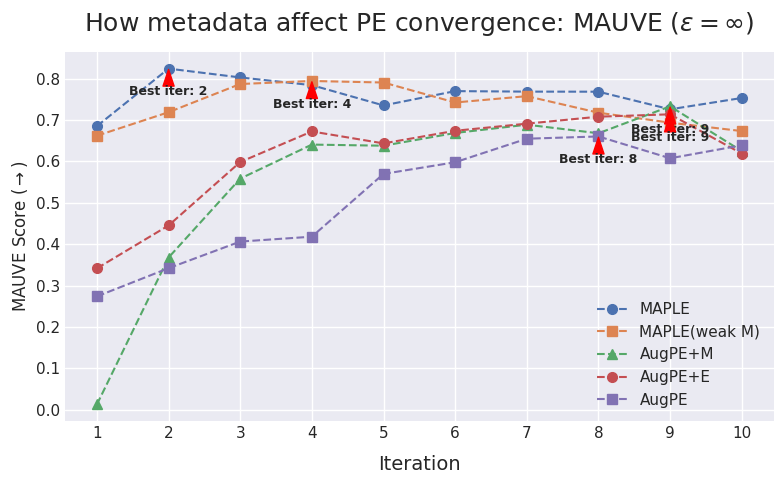

In [266]:
# --- Main execution ---
if __name__ == "__main__":
    # 1. Generate the mock data in the new dictionary format
    # (Replace this with your actual results dictionary)
    my_results_data = {#'MAPLE (with R)': np.load('./biorxiv/MetaPE/results_epsinf_5shot_50_10examples_2rand_51_noaim/MAUVE_wordJSD.npy')[:5,:2].transpose(),
                       'MAPLE': np.load('./biorxiv/MetaPE/results_epsinf_10shot_50_10examples_PE_both/MAUVE_wordJSD.npy')[:,:2].transpose(),
                       'MAPLE(weak M)': np.load('./biorxiv/MetaPE/results_epsinf_10shot_50_10examples_PE_subset2/MAUVE_wordJSD.npy')[:,:2].transpose(),
                       'AugPE+M': np.load('./biorxiv/MetaPE/results_epsinf_10shot_50_10examples_PE_noexamples/MAUVE_wordJSD.npy')[:,:2].transpose(),
                       'AugPE+E': np.load('./biorxiv/MetaPE/results_epsinf_10shot_50_10examples_PE_nometadata/MAUVE_wordJSD.npy')[:,:2].transpose(),
                       'AugPE': np.load('./biorxiv/MetaPE/results_epsinf_10shot_PE/MAUVE_wordJSD.npy')[:,:2].transpose(),
                       # 'AugPE': np.load('./biorxiv/PE/results_nonDP/MAUVE_wordJSD.npy')[:,:2].transpose()
                       }
    
    # print("Generated Mock Data (Dictionary Format):")
    # for method, data in my_results_data.items():
    #     print(f"\nMethod: {method}")
    #     print(f"  Shape: {data.shape}")
    #     print(f"  MAUVE Data (first 5): {data[0, :5]}")
    #     print(f"  JSD Data (first 5):   {data[1, :5]}")

#     print("\nPlotting results...")

    # 2. Generate and show the plot
    plot_results(my_results_data)

In [192]:
print(np.load('./biorxiv/MetaPE/results_epsinf_10shot_PE/MAUVE_wordJSD.npy')[:,:2].transpose())

[[0.2737 0.3419 0.4063 0.4181 0.5699 0.5981 0.655  0.6605 0.6077 0.6391]
 [0.4744 0.5125 0.5333 0.5628 0.5843 0.595  0.6087 0.6137 0.622  0.623 ]]


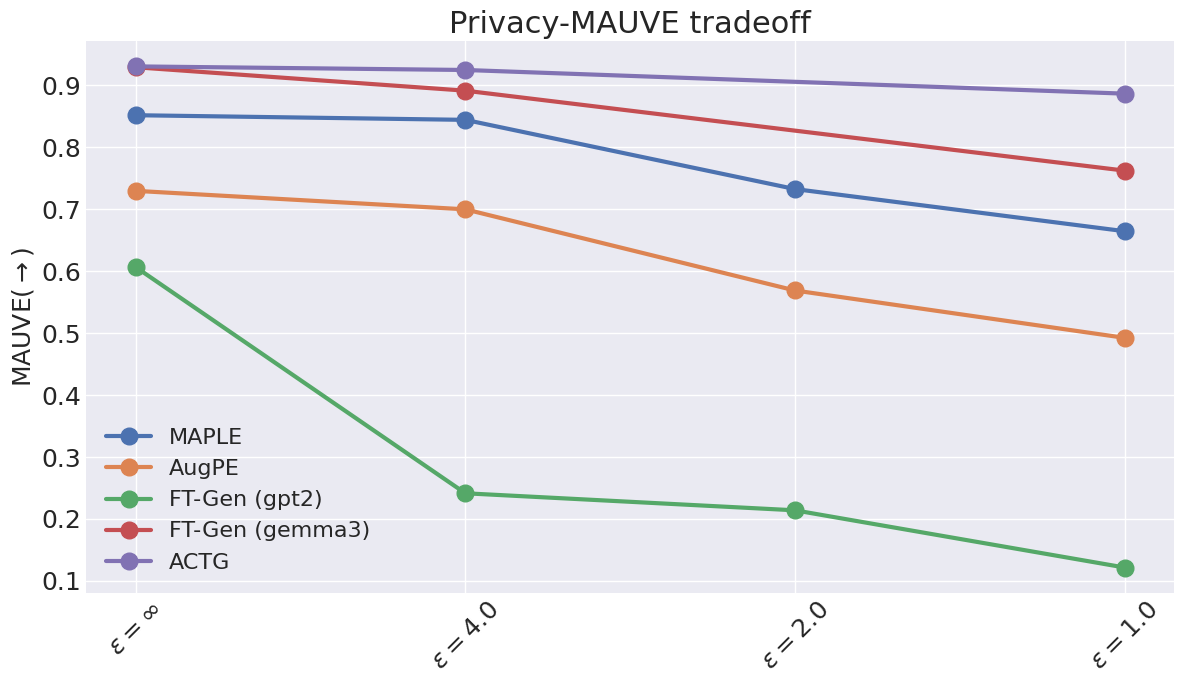

In [218]:
# privacy-MAUVE trade-off

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

def plot_results(data, x_axis_labels, font_sizes, title="Experiment Results", x_label="Methods", y_label="Values", linewidth=1.5, markersize=6):
    """
    Generates and displays a line plot for experimental results with customizable font sizes.

    Args:
        data (dict): A dictionary where keys are method names (str) and
                     values are numpy arrays of the results. The arrays can contain
                     None for missing data points.
        x_axis_labels (list): A list of strings for the x-axis ticks.
        font_sizes (dict): A dictionary to control the font sizes of plot elements.
                           Example: {'title': 20, 'xlabel': 16, 'ylabel': 16,
                                     'xticks': 12, 'yticks': 12, 'legend': 14}
        title (str or None): The title of the plot. If None, no title is shown.
        x_label (str or None): The label for the x-axis. If None, no label is shown.
        y_label (str or None): The label for the y-axis. If None, no label is shown.
        linewidth (float): The width of the plot lines.
        markersize (float): The size of the plot markers.
    """
    # Apply the default seaborn style for a clean and professional look
    sns.set_style("darkgrid")

    # Create a figure and an axes object
    fig, ax = plt.subplots(figsize=(12, 7))

    # Plot each method's results
    for method, results in data.items():
        # Filter out missing data (None) to draw continuous lines between existing points
        points = [(x, y) for x, y in zip(x_axis_labels, results) if y is not None]
        if points:
            filtered_x, filtered_y = zip(*points)
            ax.plot(filtered_x, filtered_y, marker='o', linestyle='-', label=method, linewidth=linewidth, markersize=markersize)

    # --- Font Size Customization ---
    # Set the title and axis labels with specified font sizes, if they are provided
    if title:
        ax.set_title(title, fontsize=font_sizes.get('title', 18))
    if x_label:
        ax.set_xlabel(x_label, fontsize=font_sizes.get('xlabel', 14))
    if y_label:
        ax.set_ylabel(y_label, fontsize=font_sizes.get('ylabel', 14))

    # Set the font size for tick labels
    ax.tick_params(axis='x', labelsize=font_sizes.get('xticks', 12), rotation=45)
    ax.tick_params(axis='y', labelsize=font_sizes.get('yticks', 12))

    # Add a legend with a specified font size
    ax.legend(fontsize=font_sizes.get('legend', 12))

    # Adjust plot layout to make sure everything fits without overlapping
    plt.tight_layout()

    # Display the plot
    plt.show()
    

# --- Example Usage ---
if __name__ == '__main__':
    # 1. DEFINE YOUR EXPERIMENT DATA
    # The x-axis labels for your plot
    experiment_stages = [r"$\varepsilon=\infty$", r"$\varepsilon=4.0$",r"$\varepsilon=2.0$",r"$\varepsilon=1.0$"]

    # A dictionary containing your results.
    # Each key is a method name, and the value is a NumPy array of measurements.
    results_data = {
        'MAPLE': np.array([0.8517,0.8442,0.7325,0.6645], dtype=object),
        'AugPE': np.array([0.7296,0.6998,0.5688,0.4924], dtype=object),
        'FT-Gen (gpt2)': np.array([0.6065,0.2415,0.2140,0.1217], dtype=object),
        'FT-Gen (gemma3)': np.array([0.9291,0.8913,None,0.7623], dtype=object),
        'ACTG': np.array([0.9305,0.9247,None,0.8865], dtype=object)
    }

    # 2. CUSTOMIZE FONT SIZES
    # Adjust the font sizes for different parts of the plot here.
    # You can add or remove keys as needed.
    custom_font_sizes = {
        'title': 22,
        'xlabel': 18,
        'ylabel': 18,
        'xticks': 18,
        'yticks': 18,
        'legend': 16
    }

    # 3. GENERATE THE PLOT
    # Call the function with your data and font size preferences
    plot_results(
        data=results_data,
        x_axis_labels=experiment_stages,
        font_sizes=custom_font_sizes,
        title="Privacy-MAUVE tradeoff",
        x_label=None,
        y_label=r"MAUVE$(\rightarrow)$",
        linewidth=3,
        markersize=12
    )


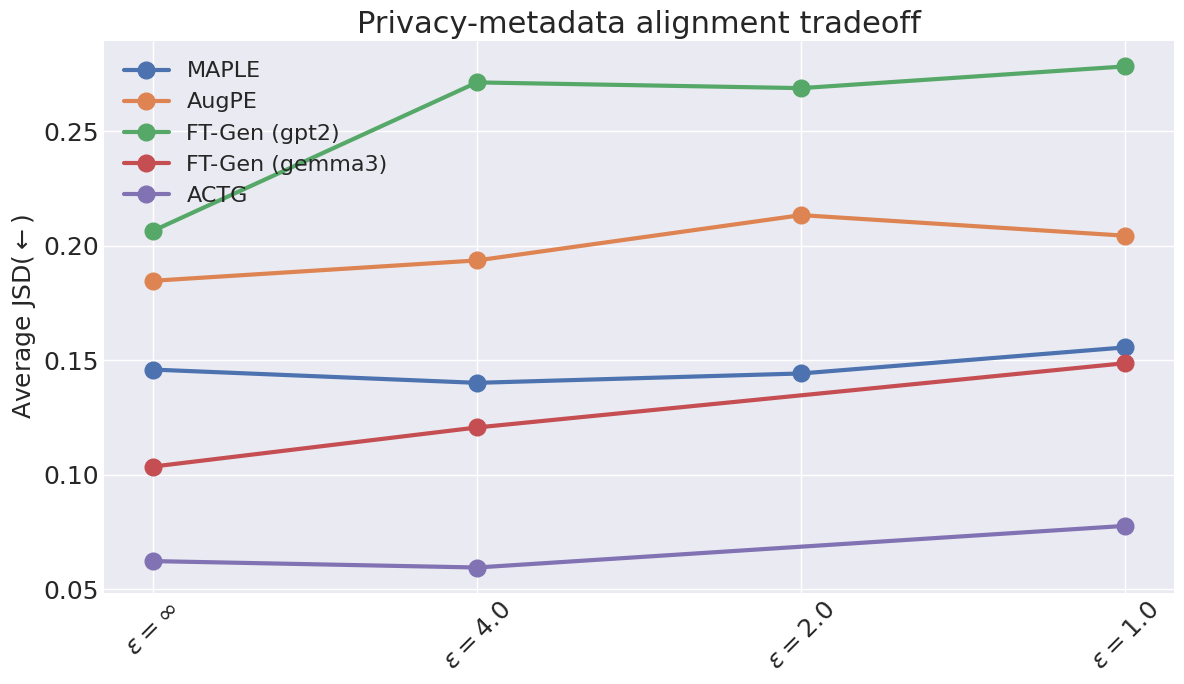

In [206]:
# --- Example Usage ---
if __name__ == '__main__':
    # 1. DEFINE YOUR EXPERIMENT DATA
    # The x-axis labels for your plot
    experiment_stages = [r"$\varepsilon=\infty$", r"$\varepsilon=4.0$",r"$\varepsilon=2.0$",r"$\varepsilon=1.0$"]

    # A dictionary containing your results.
    # Each key is a method name, and the value is a NumPy array of measurements.
    results_data = {
        'MAPLE': np.array([0.1459,0.1401,0.1442,0.1556], dtype=object),
        'AugPE': np.array([0.1847,0.1936,0.2134,0.2044], dtype=object),
        'FT-Gen (gpt2)': np.array([0.2065,0.2714,0.2689,0.2784], dtype=object),
        'FT-Gen (gemma3)': np.array([0.1035,0.1206,None,0.1487], dtype=object),
        'ACTG': np.array([0.0622,0.0594,None,0.0776], dtype=object)
    }

    # 2. CUSTOMIZE FONT SIZES
    # Adjust the font sizes for different parts of the plot here.
    # You can add or remove keys as needed.
    custom_font_sizes = {
        'title': 22,
        'xlabel': 18,
        'ylabel': 18,
        'xticks': 18,
        'yticks': 18,
        'legend': 16
    }

    # 3. GENERATE THE PLOT
    # Call the function with your data and font size preferences
    plot_results(
        data=results_data,
        x_axis_labels=experiment_stages,
        font_sizes=custom_font_sizes,
        title="Privacy-metadata alignment tradeoff",
        x_label=None,
        y_label=r"Average JSD$(\leftarrow)$",
        linewidth=3,
        markersize=12
    )

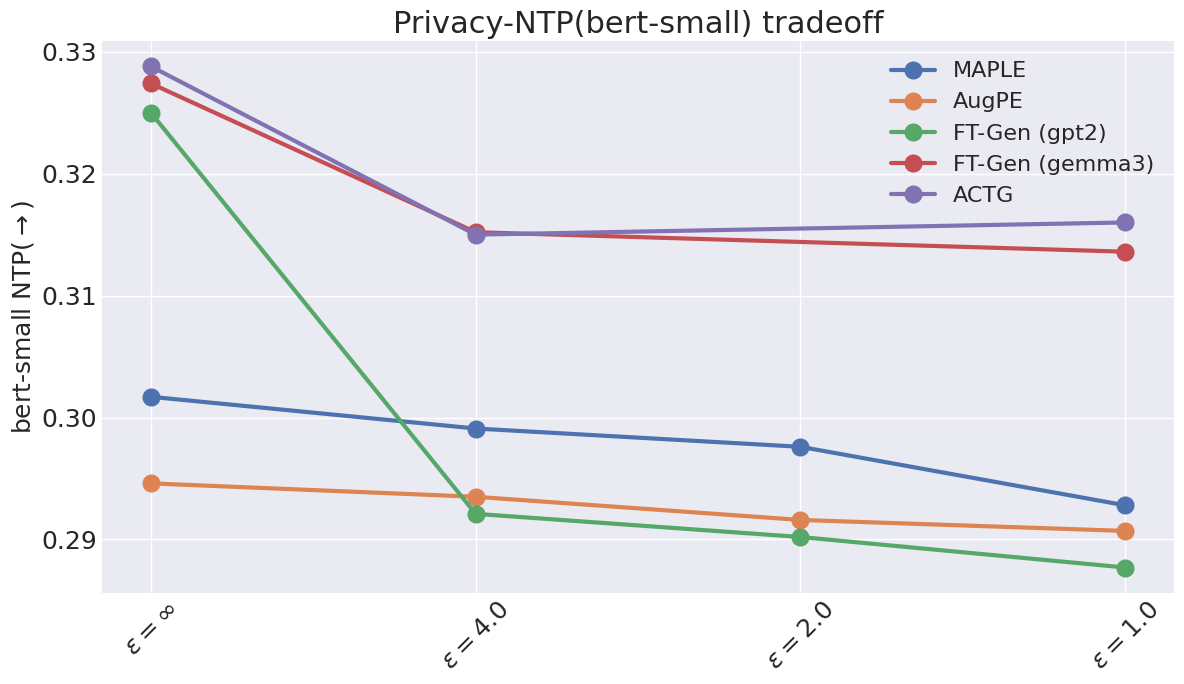

In [207]:
# --- Example Usage ---
if __name__ == '__main__':
    # 1. DEFINE YOUR EXPERIMENT DATA
    # The x-axis labels for your plot
    experiment_stages = [r"$\varepsilon=\infty$", r"$\varepsilon=4.0$",r"$\varepsilon=2.0$",r"$\varepsilon=1.0$"]

    # A dictionary containing your results.
    # Each key is a method name, and the value is a NumPy array of measurements.
    results_data = {
        'MAPLE': np.array([0.3017,0.2991,0.2976,0.2928], dtype=object),
        'AugPE': np.array([0.2946,0.2935,0.2916,0.2907], dtype=object),
        'FT-Gen (gpt2)': np.array([0.3250,0.2921,0.2902,0.2877], dtype=object),
        'FT-Gen (gemma3)': np.array([0.3274,0.3152,None,0.3136], dtype=object),
        'ACTG': np.array([0.3288,0.3150,None,0.3160], dtype=object)
    }

    # 2. CUSTOMIZE FONT SIZES
    # Adjust the font sizes for different parts of the plot here.
    # You can add or remove keys as needed.
    custom_font_sizes = {
        'title': 22,
        'xlabel': 18,
        'ylabel': 18,
        'xticks': 18,
        'yticks': 18,
        'legend': 16
    }

    # 3. GENERATE THE PLOT
    # Call the function with your data and font size preferences
    plot_results(
        data=results_data,
        x_axis_labels=experiment_stages,
        font_sizes=custom_font_sizes,
        title="Privacy-NTP(bert-small) tradeoff",
        x_label=None,
        y_label=r"bert-small NTP$(\rightarrow)$",
        linewidth=3,
        markersize=12
    )

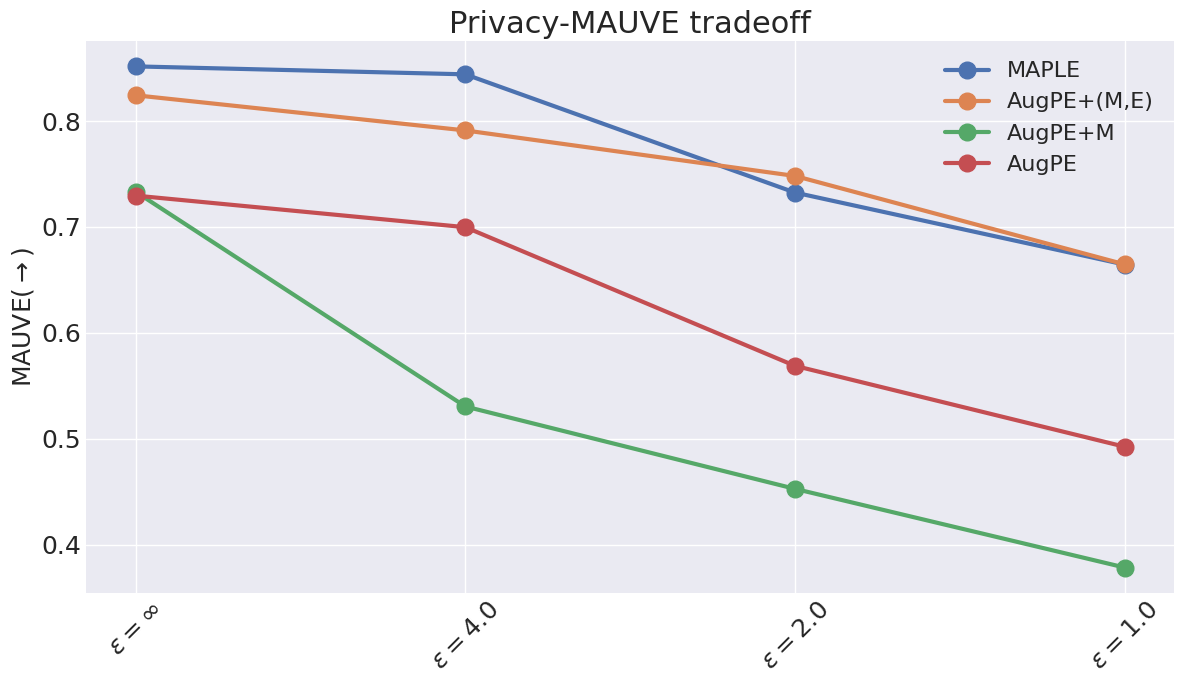

In [219]:
# --- Example Usage ---
if __name__ == '__main__':
    # 1. DEFINE YOUR EXPERIMENT DATA
    # The x-axis labels for your plot
    experiment_stages = [r"$\varepsilon=\infty$", r"$\varepsilon=4.0$",r"$\varepsilon=2.0$",r"$\varepsilon=1.0$"]

    # A dictionary containing your results.
    # Each key is a method name, and the value is a NumPy array of measurements.
    results_data = {
        'MAPLE': np.array([0.8517,0.8442,0.7325,0.6645], dtype=object),
        'AugPE+(M,E)': np.array([0.8244,0.7912,0.7482,0.6647], dtype=object),
        'AugPE+M': np.array([0.7332,0.5304,0.4526,0.3783], dtype=object),
        'AugPE': np.array([0.7296,0.6998,0.5688,0.4924], dtype=object)
    }

    # 2. CUSTOMIZE FONT SIZES
    # Adjust the font sizes for different parts of the plot here.
    # You can add or remove keys as needed.
    custom_font_sizes = {
        'title': 22,
        'xlabel': 18,
        'ylabel': 18,
        'xticks': 18,
        'yticks': 18,
        'legend': 16
    }

    # 3. GENERATE THE PLOT
    # Call the function with your data and font size preferences
    plot_results(
        data=results_data,
        x_axis_labels=experiment_stages,
        font_sizes=custom_font_sizes,
        title="Privacy-MAUVE tradeoff",
        x_label=None,
        y_label=r"MAUVE$(\rightarrow)$",
        linewidth=3,
        markersize=12
    )

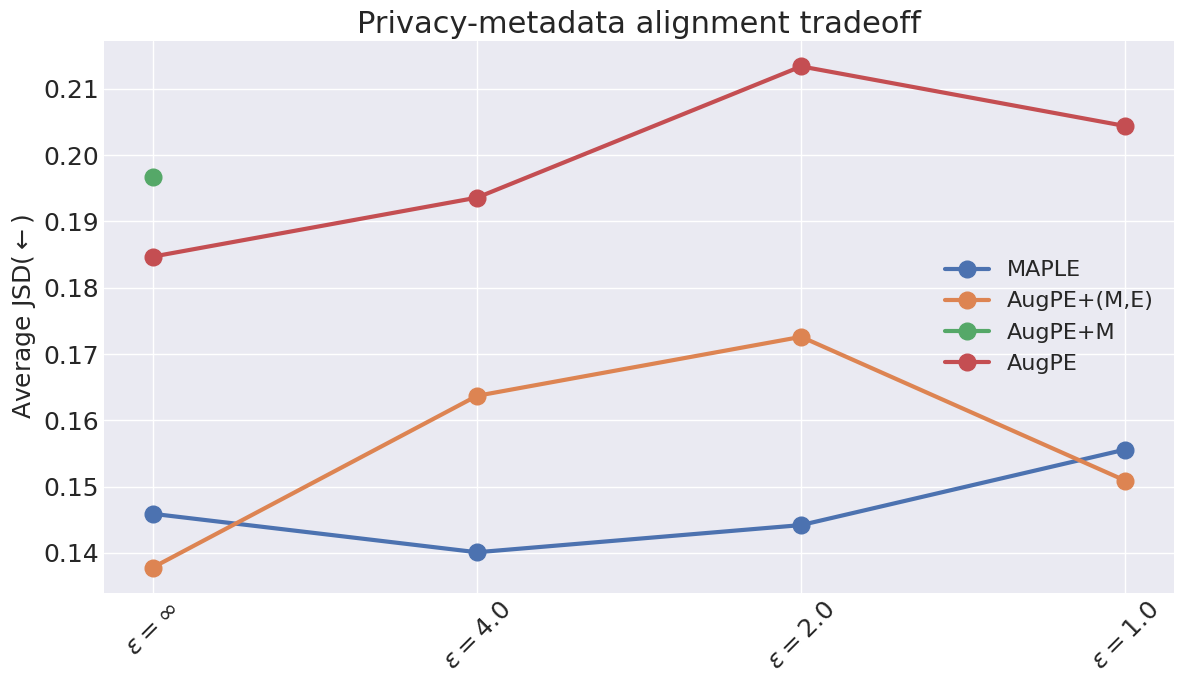

In [221]:
# --- Example Usage ---
if __name__ == '__main__':
    # 1. DEFINE YOUR EXPERIMENT DATA
    # The x-axis labels for your plot
    experiment_stages = [r"$\varepsilon=\infty$", r"$\varepsilon=4.0$",r"$\varepsilon=2.0$",r"$\varepsilon=1.0$"]

    # A dictionary containing your results.
    # Each key is a method name, and the value is a NumPy array of measurements.
    results_data = {
        'MAPLE': np.array([0.1459,0.1401,0.1442,0.1556], dtype=object),
        'AugPE+(M,E)': np.array([0.1378,0.1637,0.1726,0.1509], dtype=object),
        'AugPE+M': np.array([0.196695,None,None,None], dtype=object),
        'AugPE': np.array([0.1847,0.1936,0.2134,0.2044], dtype=object)
    }

    # 2. CUSTOMIZE FONT SIZES
    # Adjust the font sizes for different parts of the plot here.
    # You can add or remove keys as needed.
    custom_font_sizes = {
        'title': 22,
        'xlabel': 18,
        'ylabel': 18,
        'xticks': 18,
        'yticks': 18,
        'legend': 16
    }

    # 3. GENERATE THE PLOT
    # Call the function with your data and font size preferences
    plot_results(
        data=results_data,
        x_axis_labels=experiment_stages,
        font_sizes=custom_font_sizes,
        title="Privacy-metadata alignment tradeoff",
        x_label=None,
        y_label=r"Average JSD$(\leftarrow)$",
        linewidth=3,
        markersize=12
    )


Method: MAPLE [Qwen2.5 7b it], Shape: (4, 2)
[[0.489  0.4628]
 [0.4498 0.457 ]
 [0.4651 0.4487]
 [0.4268 0.4548]]

Method: Aug-PE [Qwen2.5 7b it], Shape: (4, 2)
[[0.4622 0.439 ]
 [0.4161 0.4257]
 [0.4011 0.4259]
 [0.4075 0.441 ]]

Method: Aug-PE [GPT3.5]*, Shape: (4, 2)
[[0.454 0.435]
 [0.435 0.446]
 [0.428 0.445]
 [0.419 0.431]]

Method: Aug-PE [GPT2-large]*, Shape: (4, 2)
[[0.421 0.321]
 [0.388 0.32 ]
 [0.384 0.32 ]
 [0.381 0.32 ]]

Method: FT-Gen [GPT2-large]*, Shape: (4, 2)
[[0.483 0.429]
 [0.389 0.337]
 [0.404 0.336]
 [0.386 0.321]]

Method: DPFT Downstream (full)*, Shape: (4, 2)
[[0.651 0.508]
 [0.305 0.32 ]
 [0.305 0.32 ]
 [0.305 0.32 ]]


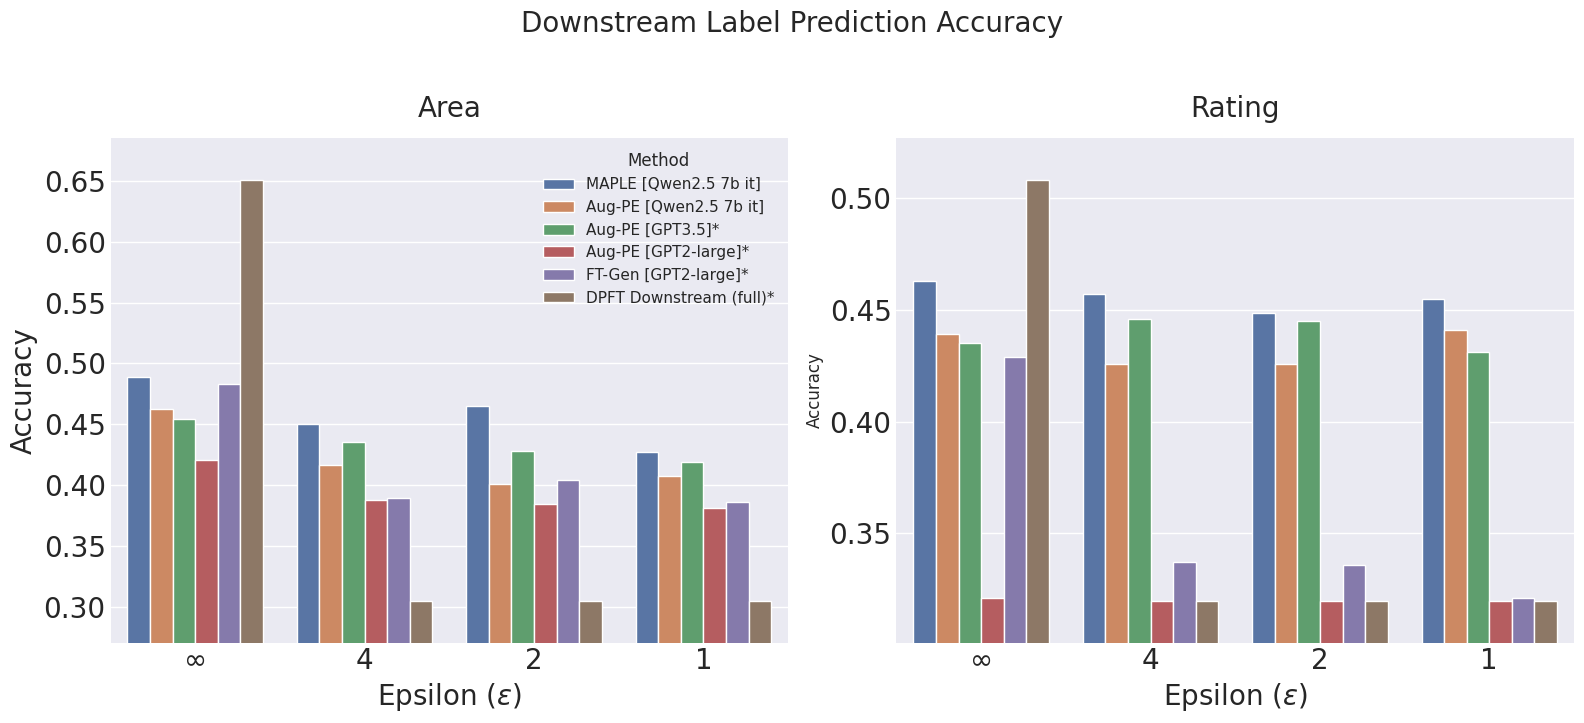

In [264]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns # Seaborn is excellent for grouped bar plots

def plot_epsilon_results(results_dict, epsilon_labels):
    """
    Creates and displays two side-by-side bar plots for score_1 and score_2.
    """
    
    # --- 1. Convert Dictionary to Long-Form DataFrame ---
    # This is the easiest way to plot grouped bars.
    data_list = []
    for method, values_array in results_dict.items():
        # values_array is shape (4, 2)
        for i, epsilon in enumerate(epsilon_labels):
            score_1 = values_array[i, 0]
            score_2 = values_array[i, 1]
            data_list.append({
                'Method': method,
                'Epsilon': epsilon,
                'Score 1': score_1,
                'Score 2': score_2
            })
    
    df = pd.DataFrame(data_list)

    # --- 2. Apply the requested style ---
    plt.style.use('seaborn-v0_8-darkgrid')

    # --- 3. Create the Subplots (1 row, 2 columns) ---
    fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(16, 7))

    # --- 4. Plot 1: Score 1 ---
    sns.barplot(
        data=df,
        x='Epsilon',
        y='Score 1',
        hue='Method',
        ax=ax1,
        order=epsilon_labels # Ensure correct order, not alphabetical
    )
    ax1.set_title('Area', fontsize=20, pad=15)
    ax1.set_xlabel(r'Epsilon ($\varepsilon$)', fontsize=20) # Use LaTeX for epsilon
    ax1.set_ylabel('Accuracy', fontsize=20)
    # Clean up the legend title
    handles, labels = ax1.get_legend_handles_labels()
    ax1.legend(handles, labels, title='Method')
    
    # --- 4. Customize Each Subplot ---
    # Automatically adjust y-axis to zoom in on the data range
    metric_scores = df['Score 1'].dropna().to_numpy()
    metric_scores = metric_scores[~np.isnan(metric_scores)]
    min_score = np.min(metric_scores)
    max_score = np.max(metric_scores)
    data_range = max_score - min_score

    # Add some padding to the top and bottom of the range
    # If all values are the same, create a small default range
    if data_range < 0.1:
        padding = 0.1 * abs(min_score) if min_score != 0 else 0.1
    else:
        # Add 10% padding to the top and bottom relative to the data range
        padding = data_range * 0.10

    # Set the y-axis limits for the current subplot
    ax1.set_ylim([min_score - padding, max_score + padding])
    
    
    # --- 5. Plot 2: Score 2 ---
    sns.barplot(
        data=df,
        x='Epsilon',
        y='Score 2',
        hue='Method',
        ax=ax2,
        order=epsilon_labels
    )
    ax2.set_title('Rating', fontsize=20, pad=15)
    ax2.set_xlabel(r'Epsilon ($\varepsilon$)', fontsize=20)
    ax2.set_ylabel('Accuracy', fontsize=12)
    ax2.get_legend().remove() # Remove redundant legend from the second plot
    
    # --- 4. Customize Each Subplot ---
    # Automatically adjust y-axis to zoom in on the data range
    metric_scores = df['Score 2'].dropna().to_numpy()
    metric_scores = metric_scores[~np.isnan(metric_scores)]
    min_score = np.min(metric_scores)
    max_score = np.max(metric_scores)
    data_range = max_score - min_score

    # Add some padding to the top and bottom of the range
    # If all values are the same, create a small default range
    if data_range < 0.1:
        padding = 0.1 * abs(min_score) if min_score != 0 else 0.1
    else:
        # Add 10% padding to the top and bottom relative to the data range
        padding = data_range * 0.10

    # Set the y-axis limits for the current subplot
    ax2.set_ylim([min_score - padding, max_score + padding])
    
    
    ax1.tick_params(axis='x', labelsize=20)
    ax1.tick_params(axis='y', labelsize=20)
    ax2.tick_params(axis='x', labelsize=20)
    ax2.tick_params(axis='y', labelsize=20)
    
    # --- 6. Final Figure Formatting ---
    fig.suptitle(r'Downstream Label Prediction Accuracy', fontsize=20, y=1.03)
    plt.tight_layout()
    plt.show()

# --- Main execution ---
if __name__ == "__main__":
    # 1. Generate the mock data
    # (Replace this with your actual results dictionary)
    my_results_data = {'MAPLE [Qwen2.5 7b it]':np.array([[0.4890,0.4498,0.4651,0.4268],[0.4628,0.457,0.4487,0.4548]]).transpose(),
                       'Aug-PE [Qwen2.5 7b it]': np.array([[0.4622,0.4161,0.4011,0.4075],[0.4390,0.4257,0.4259,0.441]]).transpose(),
                       'Aug-PE [GPT3.5]*': np.array([[0.454,0.435,0.428,0.419],[0.435,0.446,0.445,0.431]]).transpose(),
                       'Aug-PE [GPT2-large]*': np.array([[0.421,0.388,0.384,0.381],[0.321,0.320,0.320,0.320]]).transpose(),
                       'FT-Gen [GPT2-large]*':np.array([[0.483,0.389,0.404,0.386],[0.429,0.337,0.336,0.321]]).transpose(),
                       'DPFT Downstream (full)*':np.array([[0.651,0.305,0.305,0.305],[0.508,0.320,0.320,0.320]]).transpose()}
    
    for method, data in my_results_data.items():
        print(f"\nMethod: {method}, Shape: {data.shape}")
        print(data)

    # 2. Generate and show the plot
    plot_epsilon_results(my_results_data, epsilon_labels=['∞', '4', '2', '1'])



Method: MAPLE, Shape: (4, 3)
[[0.8244 0.1378 0.2992]
 [0.7912 0.1637 0.3018]
 [0.7482 0.1726 0.2997]
 [0.6647 0.1509 0.2967]]

Method: Aug-PE, Shape: (4, 3)
[[0.6605 0.2106 0.295 ]
 [0.6205 0.2166 0.2955]
 [0.5311 0.2237 0.2913]
 [0.4489 0.2292 0.293 ]]


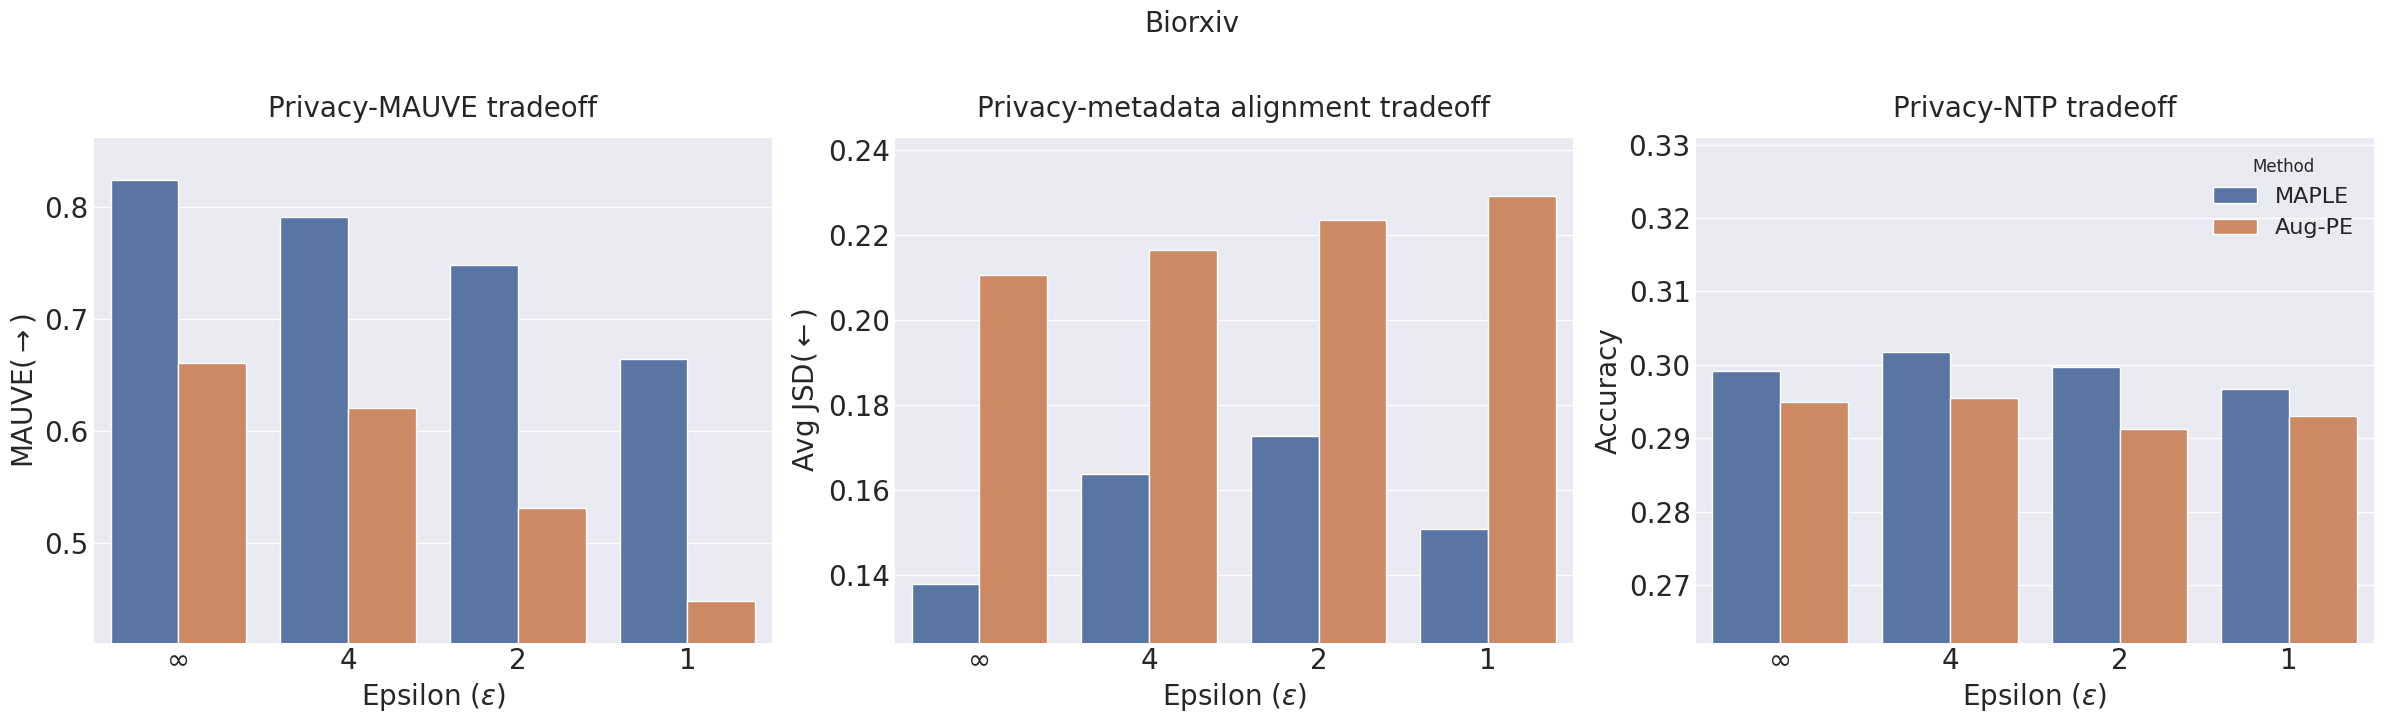

In [260]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns # Seaborn is excellent for grouped bar plots

def plot_epsilon_results(results_dict, epsilon_labels):
    """
    Creates and displays two side-by-side bar plots for score_1 and score_2.
    """
    
    # --- 1. Convert Dictionary to Long-Form DataFrame ---
    # This is the easiest way to plot grouped bars.
    data_list = []
    for method, values_array in results_dict.items():
        # values_array is shape (4, 2)
        for i, epsilon in enumerate(epsilon_labels):
            score_1 = values_array[i, 0]
            score_2 = values_array[i, 1]
            score_3 = values_array[i, 2]
            data_list.append({
                'Method': method,
                'Epsilon': epsilon,
                'Score 1': score_1,
                'Score 2': score_2,
                'Score 3': score_3
            })
    
    df = pd.DataFrame(data_list)

    # --- 2. Apply the requested style ---
    plt.style.use('seaborn-v0_8-darkgrid')

    # --- 3. Create the Subplots (1 row, 2 columns) ---
    fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(24, 7))

    # --- 4. Plot 1: Score 1 ---
    sns.barplot(
        data=df,
        x='Epsilon',
        y='Score 1',
        hue='Method',
        ax=ax1,
        order=epsilon_labels # Ensure correct order, not alphabetical
    )
    ax1.set_title('Privacy-MAUVE tradeoff', fontsize=20, pad=15)
    ax1.set_xlabel(r'Epsilon ($\varepsilon$)', fontsize=20) # Use LaTeX for epsilon
    ax1.set_ylabel(r'MAUVE($\rightarrow$)', fontsize=20)
    # Clean up the legend title
    handles, labels = ax1.get_legend_handles_labels()
    ax1.get_legend().remove()
    
    # --- 4. Customize Each Subplot ---
    # Automatically adjust y-axis to zoom in on the data range
    metric_scores = df['Score 1'].dropna().to_numpy()
    metric_scores = metric_scores[~np.isnan(metric_scores)]
    min_score = np.min(metric_scores)
    max_score = np.max(metric_scores)
    data_range = max_score - min_score

    # Add some padding to the top and bottom of the range
    # If all values are the same, create a small default range
    if data_range < 0.1:
        padding = 0.1 * abs(min_score) if min_score != 0 else 0.1
    else:
        # Add 10% padding to the top and bottom relative to the data range
        padding = data_range * 0.10

    # Set the y-axis limits for the current subplot
    ax1.set_ylim([min_score - padding, max_score + padding])
    
    # --- 5. Plot 2: Score 2 ---
    sns.barplot(
        data=df,
        x='Epsilon',
        y='Score 2',
        hue='Method',
        ax=ax2,
        order=epsilon_labels
    )
    ax2.set_title('Privacy-metadata alignment tradeoff', fontsize=20, pad=15)
    ax2.set_xlabel(r'Epsilon ($\varepsilon$)', fontsize=20)
    ax2.set_ylabel(r'Avg JSD($\leftarrow$)', fontsize=20)
    ax2.get_legend().remove() # Remove redundant legend from the second plot
    
    # --- 4. Customize Each Subplot ---
    # Automatically adjust y-axis to zoom in on the data range
    metric_scores = df['Score 2'].dropna().to_numpy()
    metric_scores = metric_scores[~np.isnan(metric_scores)]
    min_score = np.min(metric_scores)
    max_score = np.max(metric_scores)
    data_range = max_score - min_score

    # Add some padding to the top and bottom of the range
    # If all values are the same, create a small default range
    if data_range < 0.1:
        padding = 0.1 * abs(min_score) if min_score != 0 else 0.1
    else:
        # Add 10% padding to the top and bottom relative to the data range
        padding = data_range * 0.10

    # Set the y-axis limits for the current subplot
    ax2.set_ylim([min_score - padding, max_score + padding])
    
    # --- 5. Plot 3: Score 3 ---
    sns.barplot(
        data=df,
        x='Epsilon',
        y='Score 3',
        hue='Method',
        ax=ax3,
        order=epsilon_labels
    )
    
    # --- 4. Customize Each Subplot ---
    # Automatically adjust y-axis to zoom in on the data range
    metric_scores = df['Score 3'].dropna().to_numpy()
    metric_scores = metric_scores[~np.isnan(metric_scores)]
    min_score = np.min(metric_scores)
    max_score = np.max(metric_scores)
    data_range = max_score - min_score

    # Add some padding to the top and bottom of the range
    # If all values are the same, create a small default range
    if data_range < 0.1:
        padding = 0.1 * abs(min_score) if min_score != 0 else 0.1
    else:
        # Add 10% padding to the top and bottom relative to the data range
        padding = data_range * 0.10

    # Set the y-axis limits for the current subplot
    ax3.set_ylim([min_score - padding, max_score + padding])
    
    ax3.set_title('Privacy-NTP tradeoff', fontsize=20, pad=15)
    ax3.set_xlabel(r'Epsilon ($\varepsilon$)', fontsize=20)
    ax3.set_ylabel(r'Accuracy', fontsize=20)
    ax3.legend(handles, labels, title='Method', fontsize=16)
    
    ax1.tick_params(axis='x', labelsize=20)
    ax1.tick_params(axis='y', labelsize=20)
    ax2.tick_params(axis='x', labelsize=20)
    ax2.tick_params(axis='y', labelsize=20)
    ax3.tick_params(axis='x', labelsize=20)
    ax3.tick_params(axis='y', labelsize=20)
    
    # --- 6. Final Figure Formatting ---
    fig.suptitle(r'Biorxiv', fontsize=20, y=1.03)
    plt.tight_layout()
    plt.show()

# --- Main execution ---
if __name__ == "__main__":
    # 1. Generate the mock data
    # (Replace this with your actual results dictionary)
    my_results_data = {'MAPLE':np.array([[0.8244,0.7912,0.7482,0.6647],[0.1378,0.1637,0.1726,0.1509],[0.2992,0.3018,0.2997,0.2967]]).transpose(),
                       'Aug-PE': np.array([[0.6605,0.6205,0.5311,0.4489],[0.2106,0.2166,0.2237,0.2292],[0.2950,0.2955,0.2913,0.2930]]).transpose(),
                      }
    for method, data in my_results_data.items():
        print(f"\nMethod: {method}, Shape: {data.shape}")
        print(data)

    # 2. Generate and show the plot
    plot_epsilon_results(my_results_data, epsilon_labels=['∞', '4', '2', '1'])


Method: MAPLE, Shape: (4, 3)
[[0.8244 0.1378 0.2992]
 [0.7912 0.1637 0.3018]
 [0.7482 0.1726 0.2997]
 [0.6647 0.1509 0.2967]]

Method: Aug-PE, Shape: (4, 3)
[[0.6605 0.2106 0.295 ]
 [0.6205 0.2166 0.2955]
 [0.5311 0.2237 0.2913]
 [0.4489 0.2292 0.293 ]]

Method: ACTG, Shape: (4, 3)
[[0.9305 0.0622 0.3288]
 [0.9247 0.0594 0.325]
 [None None None]
 [0.8865 0.0776 0.316]]


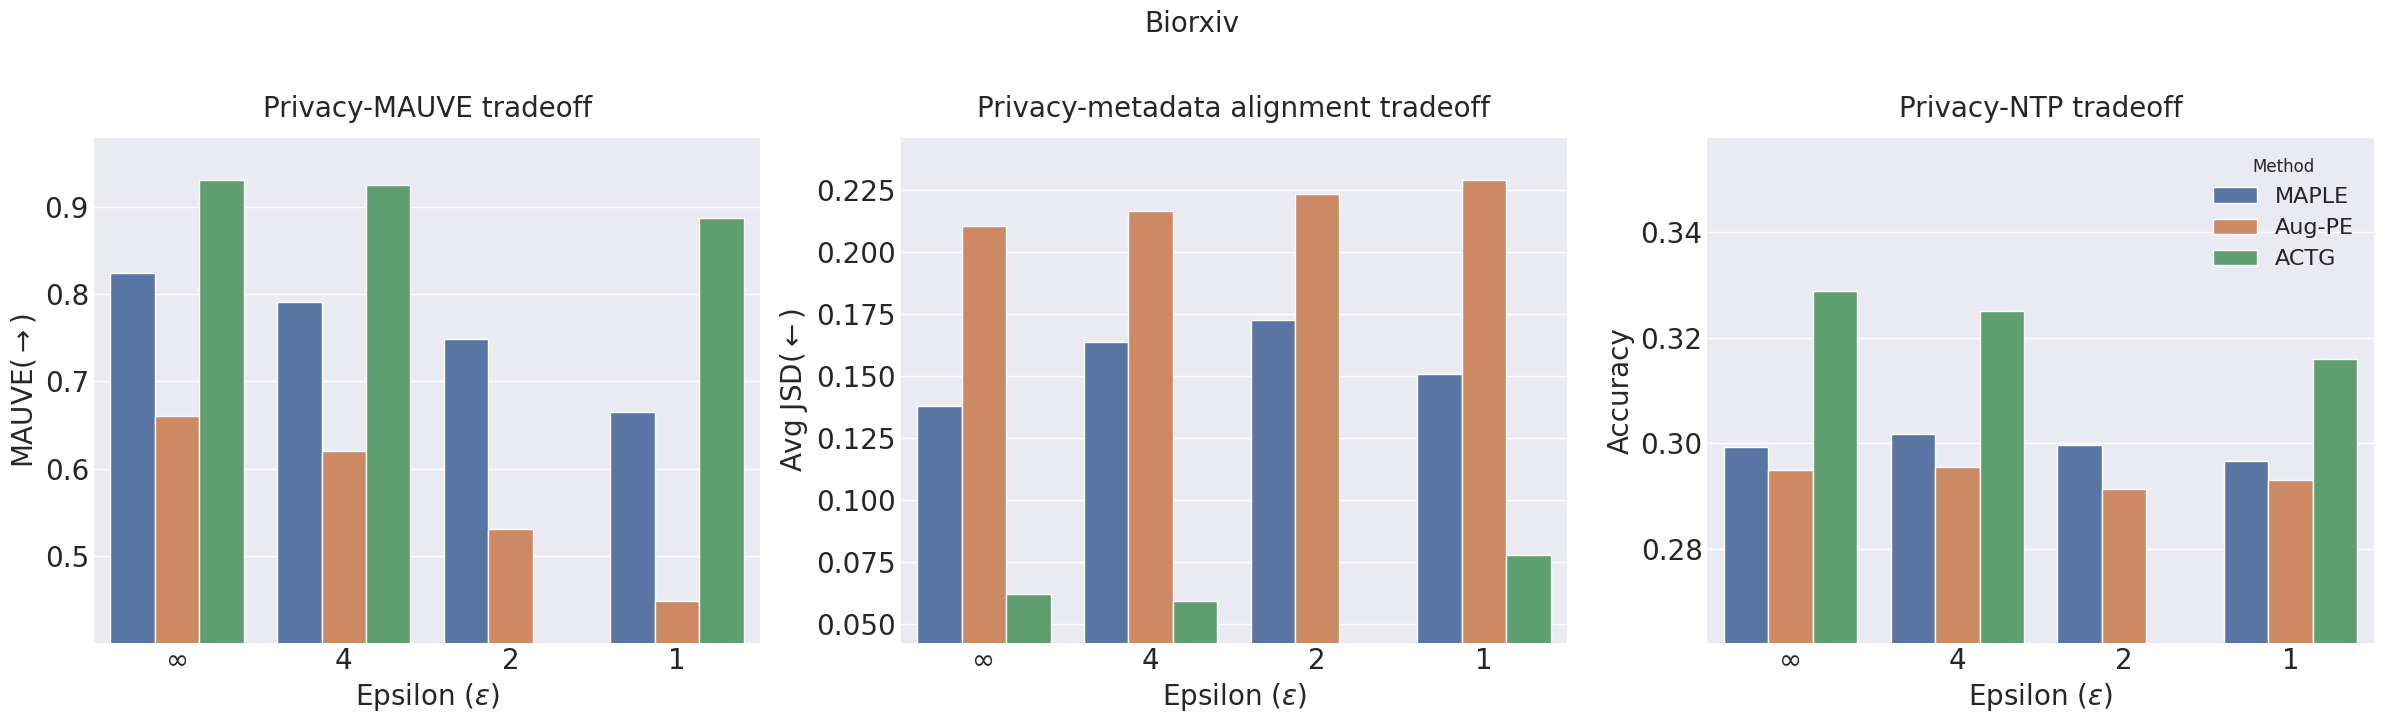

In [261]:
# --- Main execution ---
if __name__ == "__main__":
    # 1. Generate the mock data
    # (Replace this with your actual results dictionary)
    my_results_data = {'MAPLE':np.array([[0.8244,0.7912,0.7482,0.6647],[0.1378,0.1637,0.1726,0.1509],[0.2992,0.3018,0.2997,0.2967]]).transpose(),
                       'Aug-PE': np.array([[0.6605,0.6205,0.5311,0.4489],[0.2106,0.2166,0.2237,0.2292],[0.2950,0.2955,0.2913,0.2930]]).transpose(),
                       'ACTG': np.array([[0.9305,0.9247,None,0.8865],[0.0622,0.0594,None,0.0776],[0.3288,0.3250,None,0.3160]]).transpose(),
                      }
    for method, data in my_results_data.items():
        print(f"\nMethod: {method}, Shape: {data.shape}")
        print(data)

    # 2. Generate and show the plot
    plot_epsilon_results(my_results_data, epsilon_labels=['∞', '4', '2', '1'])

## Biorxiv, Main results


| Biorxiv | MAUVE (t5, 1024\) | JSD word\_count | Avg JSD annotated metadata | NTP  (bert-small) |
| :---- | :---- | :---- | :---- | :---- |
| Training data (2000) \[Upper bound\] | 0.9635 |  |  | 0.3387 |
| FT-Gen \[GPT2\] | 0.6065 | 0.617474 | 0.206536 | 0.3250 |
| DP-FT-Gen  \[GPT2, eps=4.0\] | 0.2415 | 0.651943 | 0.271403 | 0.2921 |
| DP-FT-Gen  \[GPT2, eps=2.0\] | 0.2140 | 0.647282 | 0.268985 | 0.2902 |
| DP-FT-Gen  \[GPT2, eps=1.0\] | 0.1217 | 0.617600 | 0.278493 | 0.2877 |
| FT-Gen \[gemma3\_1b\_pt\] | 0.9324 | 0.104590 | 0.103552 | 0.3273 |
| DP-FT-Gen  \[gemma3\_1b\_pt, eps=4.0\] | 0.8633 | 0.088075 | 0.120689 | 0.3166 |
| DP-FT-Gen  \[gemma3\_1b\_pt, eps=1.0\] | 0.7769 | 0.119686 | 0.148731 | 0.3136 |
| ACTG  \[gemma3\_1b\_pt\] | 0.9305 | 0.099936 | 0.062269 | 0.3288 |
| ACTG  \[gemma3\_1b\_pt, eps=4.0\] | 0.9247 | 0.103487 | 0.059412 | 0.3150 |
| ACTG \[gemma3\_1b\_pt, eps=1.0\] | 0.8865 | 0.107107 | 0.077690 | 0.3160 |
| MAPLE  eps=inf (1, 10 shots) | 0.8244 | 0.171581 | 0.137813 | 0.2992 |
| MAPLE  eps=4.0 (2, 5 shots) | 0.7912 | 0.3161 | 0.163754 | 0.3018 |
| MAPLE eps=2.0 (2, 5 shots) | 0.7482 | 0.2798 | 0.172697 | 0.2997 |
| MAPLE  eps=1.0 (1, 3 shots) | 0.6647 | 0.099 | 0.150932 | 0.2967 |
| Aug-PE, eps=inf (7) | 0.6605 | 0.6137 | 0.210624 | 0.2950 |
| Aug-PE, eps=4.0 (8) | 0.6204 | 0.6246 | 0.216626 | 0.2955 |
| Aug-PE, eps=2.0 (8) | 0.5311 | 0.6221 | 0.223927 | 0.2913 |
| Aug-PE, eps=1.0 (7) | 0.4489 | 0.5709 | 0.229239 | 0.2930 |

## Biorxiv, main ablation

| Biorxiv, eps=inf | MAUVE (t5, 1024\) | JSD word\_count | Avg JSD annotated metadata | NTP  (bert-small) |
| :---- | :---- | :---- | :---- | :---- |
| MAPLE  eps=inf (1, 10 shots) | 0.8244 | 0.171581 | 0.137813 | 0.2992 |
| Aug-PE+E (8) | 0.7140 | 0.543665 | 0.201631 | 0.2981 |
| Aug-PE+M (8) | 0.7332 | 0.588132 | 0.196695 | 0.2940 |
| Aug-PE (7) | 0.6605 | 0.6137 | 0.210624 | 0.2950 |
| 0 shot (M,E) | 0.3813 | 0.329066 | 0.179367 | 0.2836 |
| 0 shot (M) | 0.0381 | 0.568422 | 0.256141 | 0.2341 |
| 0 shot (E) | 0.0998 | 0.235598 | 0.317744 | 0.2835 |
| 0 shot (None) | 0.0626 | 0.470440 | 0.314848 | 0.2753 |

## Biorxiv, subset of metadata

| Biorxiv, nonDP | MAUVE (t5, 1024\) | JSD word\_count | Avg JSD annotated metadata | NTP  (bert-small) |
| :---- | :---- | :---- | :---- | :---- |
| Full metadata (8) \[MAPLE\] | 0.8244 | 0.171581 | 0.137813 | 0.2992 |
| Weak metadata (2) \[MAPLE\] | 0.7945 | 0.288579 | 0.157225 | 0.3004 |
| No metadata (0) \[AugPE+E\] | 0.7140 | 0.543665 | 0.201631 | 0.2981 |

## Openreview, main result

| Openreview | Prediction: Area | Prediction: Rating |
| ----- | :---- | :---- |
| MAPLE, eps=inf, (0) | **0.4890** | **0.4628** |
| MAPLE, eps=4.0, (0) 3 shots | **0.4498** | **0.457** |
| MAPLE, eps=2.0, (1) 3 shots | **0.4651** | **0.4487** |
| MAPLE, eps=1.0, (1) 3 shots | **0.4268** | **0.4548** |
| Aug-PE, eps=inf (1) | **0.4622** | **0.439** |
| Aug-PE, eps=4.0 (1) | **0.4161** | **0.4257** |
| Aug-PE, eps=2.0 (1) | **0.4011** | **0.4259** |
| Aug-PE, eps=1.0 (1) | **0.4075** | **0.441** |
| \[Below are reported results in the Aug-PE paper.\] |  |  |
| Training data (8396/full) \[Upper bound\] | 0.651 | 0.508 |
| eps=4.0 | 0.305 | 0.320 |
| eps=2.0 | 0.305 | 0.320 |
| eps=1.0 | 0.305 | 0.320 |
| Training data (2000) \[Upper bound\] | 0.553 | 0.478 |
| eps=4.0 | 0.305 | 0.320 |
| eps=2.0 | 0.304 | 0.255 |
| eps=1.0 | 0.063 | 0.198 |
| FT-Gen \[GPT2-large\] | 0.483 | 0.429 |
| DP-FT-Gen  \[GPT2-large, eps=4.0\] | 0.389 | 0.337 |
| DP-FT-Gen  \[GPT2-large, eps=2.0\] | 0.404 | 0.336 |
| DP-FT-Gen  \[GPT2-large, eps=1.0\] | 0.386 | 0.321 |
| Aug-PE \[GPT3.5\], eps=inf | 0.454 | 0.435 |
| Aug-PE \[GPT3.5\], eps=4.0 | 0.435 | 0.446 |
| Aug-PE \[GPT3.5\], eps=2.0 | 0.428 | 0.445 |
| Aug-PE \[GPT3.5\], eps=1.0 | 0.419 | 0.431 |